## 1. Data Loading and Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('WA_Fn-UseC_-Telco-Customer-Churn.xlsx')
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print(df.columns.tolist())
df.dtypes

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

**Target variable:** `Churn` (Yes = customer left, No = customer stayed).
Important columns: `tenure` = months with the company, `MonthlyCharges`/`TotalCharges` = billing amount,
`Contract`/`PaymentMethod`/`InternetService` etc. = the services and plan the customer has.

## 2. Data Preprocessing

In [5]:
print("Missing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTotalCharges dtype:", df['TotalCharges'].dtype)

Missing values:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

TotalCharges dtype: str


In [6]:
# TotalCharges has blank strings for new customers (tenure=0), so pandas reads it as text.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Missing after conversion:", df['TotalCharges'].isnull().sum())
df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges']]

Missing after conversion: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [7]:
# tenure=0 means no bill yet, so it's genuinely 0, not missing -> fill with 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# customerID is a unique identifier, not useful for prediction -> drop it
df = df.drop(columns=['customerID'])

# remove exact duplicate rows if any
df = df.drop_duplicates()

# 'No internet/phone service' means the same as 'No' for these add-on columns -> simplify
service_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                 'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in service_cols:
    df[col] = df[col].replace('No internet service', 'No')
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')

print("Final shape after cleaning:", df.shape)
df.head()

Final shape after cleaning: (7021, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Exploratory Data Analysis

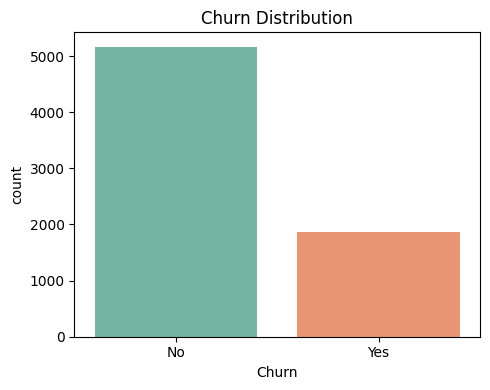

Churn
No     73.6
Yes    26.4
Name: proportion, dtype: float64


In [8]:
plt.figure(figsize=(5, 4))
sns.countplot(x='Churn', data=df, hue='Churn', palette='Set2', legend=False)
plt.title('Churn Distribution')
plt.tight_layout()
plt.show()

print(df['Churn'].value_counts(normalize=True).round(3) * 100)

About 26.6% of customers churned — the classes are imbalanced (~3:1).

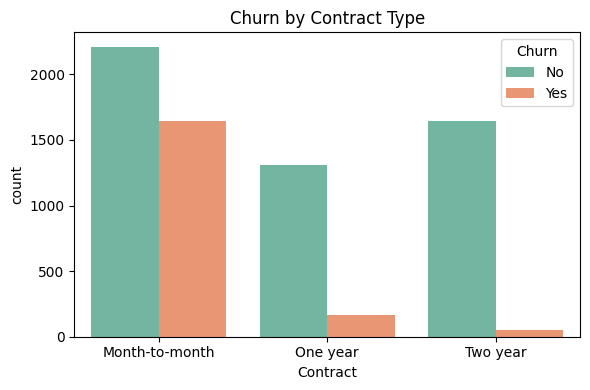

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Contract', hue='Churn', data=df, palette='Set2')
plt.title('Churn by Contract Type')
plt.tight_layout()
plt.show()

Month-to-month customers churn far more than one/two-year contract customers.

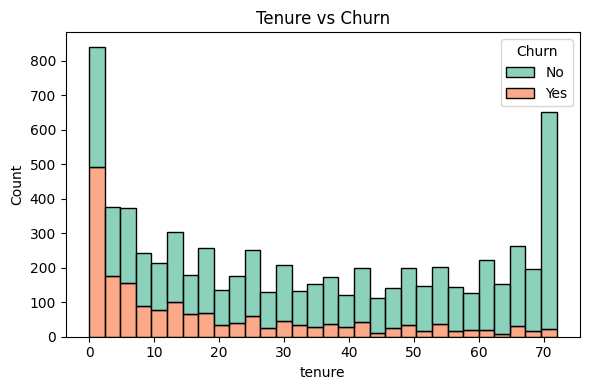

In [10]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack', palette='Set2')
plt.title('Tenure vs Churn')
plt.tight_layout()
plt.show()

Customers who churn tend to have low tenure (they leave early).

## 4. Feature Engineering and Encoding

In [11]:
from sklearn.preprocessing import LabelEncoder

model_df = df.copy()
model_df['Churn'] = model_df['Churn'].map({'Yes': 1, 'No': 0})

categorical_cols = model_df.select_dtypes(include='object').columns.tolist()
binary_cols = [c for c in categorical_cols if model_df[c].nunique() == 2]
multi_cols = [c for c in categorical_cols if model_df[c].nunique() > 2]

le = LabelEncoder()
for col in binary_cols:
    model_df[col] = le.fit_transform(model_df[col])

model_df = pd.get_dummies(model_df, columns=multi_cols, drop_first=True)
print("Shape after encoding:", model_df.shape)
model_df.head()

Shape after encoding: (7021, 24)


/tmp/ipykernel_99/3516506622.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = model_df.select_dtypes(include='object').columns.tolist()


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,29.85,29.85,0,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,1,0,1,...,56.95,1889.50,0,False,False,True,False,False,False,True
2,1,0,0,0,2,1,0,1,1,0,...,53.85,108.15,1,False,False,False,False,False,False,True
3,1,0,0,0,45,0,0,1,0,1,...,42.30,1840.75,0,False,False,True,False,False,False,False
4,0,0,0,0,2,1,0,0,0,0,...,70.70,151.65,1,True,False,False,False,False,True,False


In [12]:
X = model_df.drop(columns=['Churn'])
y = model_df['Churn']
print("X:", X.shape, " y:", y.shape)

X: (7021, 23)  y: (7021,)


## 5. Training and Testing

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_features] = scaler.fit_transform(X_train[numeric_features])
X_test_scaled[numeric_features] = scaler.transform(X_test[numeric_features])

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5616, 23)  Test: (1405, 23)


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Models trained.")

Models trained.


## 6. Model Evaluation

In [15]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

def evaluate(name, y_true, y_pred):
    print(f"--- {name} ---")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall   :", round(recall_score(y_true, y_pred), 4))
    print("F1-Score :", round(f1_score(y_true, y_pred), 4))
    print()

evaluate("Logistic Regression", y_test, y_pred_lr)
evaluate("Random Forest", y_test, y_pred_rf)

--- Logistic Regression ---
Accuracy : 0.8021
Precision: 0.6599
Recall   : 0.5215
F1-Score : 0.5826

--- Random Forest ---
Accuracy : 0.7851
Precision: 0.6316
Recall   : 0.4516
F1-Score : 0.5266



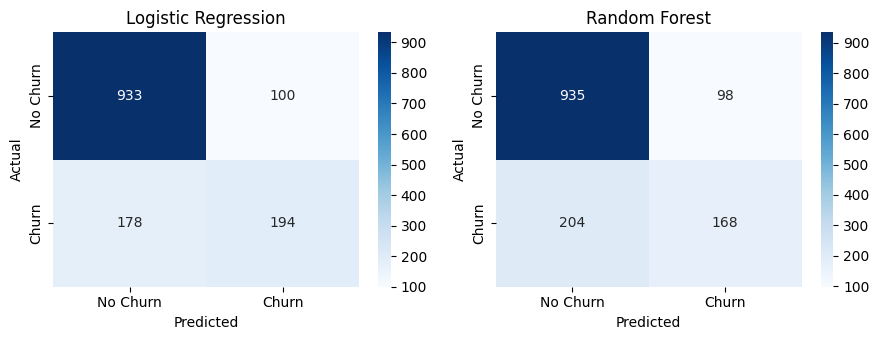

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, y_pred) in zip(axes, [("Logistic Regression", y_pred_lr), ("Random Forest", y_pred_rf)]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [17]:
print(classification_report(y_test, y_pred_lr, target_names=['No Churn', 'Churn']))
print(classification_report(y_test, y_pred_rf, target_names=['No Churn', 'Churn']))

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1033
       Churn       0.66      0.52      0.58       372

    accuracy                           0.80      1405
   macro avg       0.75      0.71      0.73      1405
weighted avg       0.79      0.80      0.79      1405

              precision    recall  f1-score   support

    No Churn       0.82      0.91      0.86      1033
       Churn       0.63      0.45      0.53       372

    accuracy                           0.79      1405
   macro avg       0.73      0.68      0.69      1405
weighted avg       0.77      0.79      0.77      1405



Logistic Regression has a better F1-score than Random Forest here, so it is chosen as the
final model. In churn prediction, recall on the churn class matters most (missing a churner
is costlier than a false alarm), and Logistic Regression balances this best.

In [18]:
final_model = log_reg
final_uses_scaled = True
print("Final model: Logistic Regression")

Final model: Logistic Regression


## 7. Application / Prediction

In [19]:
sample = X_test.sample(5, random_state=1)
sample_scaled = X_test_scaled.loc[sample.index]

preds = final_model.predict(sample_scaled)
probs = final_model.predict_proba(sample_scaled)[:, 1]

result = sample[['tenure', 'MonthlyCharges', 'TotalCharges']].copy()
result['Actual'] = y_test.loc[sample.index].map({1: 'Yes', 0: 'No'}).values
result['Predicted'] = pd.Series(preds, index=sample.index).map({1: 'Yes', 0: 'No'})
result['Churn_Probability'] = probs.round(3)
result

,tenure,MonthlyCharges,TotalCharges,Actual,Predicted,Churn_Probability
882,6,83.90,497.55,Yes,Yes,0.617
2746,31,21.00,697.70,No,No,0.011
1104,42,19.55,839.40,No,No,0.020
5291,68,86.45,5762.95,No,No,0.065
3019,22,55.15,1206.05,Yes,No,0.133


In [20]:
def predict_new_customer(customer_dict):
    new_df = pd.DataFrame([customer_dict])
    for col in service_cols:
        if col in new_df.columns:
            new_df[col] = new_df[col].replace('No internet service', 'No')
    if 'MultipleLines' in new_df.columns:
        new_df['MultipleLines'] = new_df['MultipleLines'].replace('No phone service', 'No')

    for col in binary_cols:
        new_df[col] = le.fit(df[col]).transform(new_df[col])
    new_df = pd.get_dummies(new_df, columns=[c for c in multi_cols if c in new_df.columns])
    new_df = new_df.reindex(columns=X.columns, fill_value=0)
    new_df[numeric_features] = scaler.transform(new_df[numeric_features])

    pred = final_model.predict(new_df)[0]
    prob = final_model.predict_proba(new_df)[0, 1]
    return ('Churn' if pred == 1 else 'No Churn'), round(prob, 3)

example_customer = {
    'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No',
    'tenure': 2, 'PhoneService': 'Yes', 'MultipleLines': 'No',
    'InternetService': 'Fiber optic', 'OnlineSecurity': 'No', 'OnlineBackup': 'No',
    'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'Yes',
    'StreamingMovies': 'Yes', 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check', 'MonthlyCharges': 95.5, 'TotalCharges': 191.0
}

prediction, probability = predict_new_customer(example_customer)
print("Prediction:", prediction, " | Churn probability:", probability)

Prediction: Churn  | Churn probability: 0.76


## Conclusion
Logistic Regression performed best (Accuracy ~80%, F1 ~0.58). Customers on month-to-month
contracts with short tenure and high monthly charges are most likely to churn. The model can
be used by the company to flag at-risk customers each month and target them with retention
offers.